# Phases 3 and 4: Response and Uplift Models

**Phase 3 goal:** build the conventional "likely to purchase" ranking, `m1(X) = P(target = 1 given X, treatment_flg = 1)`, and lock its setup.

The notebook needs the Parquet files from `01_experiment_audit.ipynb` and `02_feature_engineering.ipynb`. It runs in this order: check the selection logic on known answers, load the treated development customers, tune, measure performance, check calibration, review leakage, and apply the rules. The rules were committed in `reports/decisions.md` before tuning first ran.

Phase 3 saves no model and uses no control or holdout rows, and it never loads their labels.

`target` means a purchase in an undocumented period after communication, and `treatment_flg` records SMS communication status. Phase 4 starts after the Phase 3 conclusion. It runs in the same pass, because its match assertion uses Phase 3 scores held in memory.

## Setup

In [1]:
import hashlib
import os
import re
import shutil
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import log_loss, roc_auc_score
from xgboost import XGBClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

sys.path.insert(0, str(ROOT / "notebooks"))
from targeting import FREEZE_TOLERANCE, arm_balance, assert_exact_tau, check_freeze, holdout_score_hash, score_ranks, select_by_rank, select_top_k

TABLES = Path("outputs/tables")
FIGURES = Path("outputs/figures")
PROCESSED = Path("data/processed")
FEATURES_PATH = PROCESSED / "customer_features.parquet"
SPLITS_PATH = PROCESSED / "splits.parquet"
LABELS_PATH = PROCESSED / "uplift_train.parquet"

SEED = 42
BOOTSTRAP_RESAMPLES = 2_000
EXPECTED_TREATED_DEVELOPMENT = 79_985
EXPECTED_HOLDOUT = 40_008
EXPECTED_FOLD_SIZES = {1: 15_998, 2: 15_997, 3: 15_997, 4: 15_997, 5: 15_996}
FOLDS = sorted(EXPECTED_FOLD_SIZES)
FOLD_COLUMNS = [f"fold_{fold}" for fold in FOLDS]

# The locked Phase 2 list, in stored order, with the three express features the inclusion rule admitted.
FEATURE_NAMES = [
    "days_since_last_purchase", "days_since_first_observed_purchase",
    "txn_count_hist", "txn_count_7d", "txn_count_14d", "txn_count_30d", "txn_count_60d", "txn_count_90d",
    "active_days_hist", "avg_gap_days",
    "spend_hist", "spend_30d", "spend_60d", "spend_90d",
    "avg_basket_value", "max_basket_value", "std_basket_value",
    "txn_trend_30d", "spend_trend_30d",
    "avg_lines_per_basket", "distinct_products_hist", "distinct_stores_hist",
    "weekend_txn_share", "txn_share_05_09", "txn_share_10_13", "txn_share_14_19",
    "regular_points_received_hist", "regular_points_spent_hist",
    "express_points_received_hist", "express_points_spent_hist",
    "regular_points_spent_30d", "express_points_spent_30d",
    "age", "age_invalid_flg", "gender_f", "gender_m", "gender_u",
    "days_since_first_issue", "pre_issue_purchase_flg",
]
assert len(FEATURE_NAMES) == 39

FIXED_SETTINGS = {
    "objective": "binary:logistic",
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "random_state": SEED,
    "reg_lambda": 1,
    "reg_alpha": 0,
    "gamma": 0,
    "n_jobs": 8,
}
GRID = [
    {"max_depth": depth, "min_child_weight": weight}
    for depth in (2, 3, 4, 6)
    for weight in (10, 100)
]
FIRST_TREE_CAP = 1_500
SECOND_TREE_CAP = 3_000

GAIN_STOP = 0.50
SINGLE_FEATURE_AUC_STOP = 0.80
OVERALL_AUC_STOP = 0.90
SLOPE_RANGE = (0.9, 1.1)
BIN_GAP_FLAG_POINTS = 2.0

SURFACE, INK, INK_SECONDARY, MUTED, GRIDLINE, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": "sans-serif",
        "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
        "font.size": 10,
        "text.color": INK,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRIDLINE,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK_SECONDARY,
        "ytick.labelcolor": INK_SECONDARY,
        "legend.frameon": False,
        "lines.linewidth": 1.6,
    }
)
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_rows", 200, "display.max_colwidth", 70)

## 1. Known-answer checks

The rules for the tree count and the setting, and the fast bootstrap AUC, run on small constructed inputs first. Every result must match a value worked out by hand.

In [2]:
def best_tree_count(fold_curves):
    """Tree count with the lowest mean validation log-loss. argmin keeps the earliest on a tie."""
    return int(np.argmin(np.asarray(fold_curves).mean(axis=0))) + 1


def locked_tree_count(curves_for_cap):
    """Applies the cap rule. Returns the cap used, the tree count and the curves."""
    cap = FIRST_TREE_CAP
    curves = curves_for_cap(cap)
    trees = best_tree_count(curves)
    if trees == FIRST_TREE_CAP:
        cap = SECOND_TREE_CAP
        curves = curves_for_cap(cap)
        trees = best_tree_count(curves)
        if trees == SECOND_TREE_CAP:
            raise RuntimeError(f"A setting reached the {SECOND_TREE_CAP:,}-tree cap twice. Stop and escalate.")
    return cap, trees, curves


def choose_setting(results):
    """Simplest setting within one SE of the best, using paired fold differences.

    `results` has one row per setting, with max_depth, min_child_weight, tree_count and the fold columns.
    """
    folds = results[FOLD_COLUMNS].to_numpy(dtype=float)
    means = folds.mean(axis=1)
    differences = folds - folds[means.argmin()]

    table = results.copy()
    table["mean_log_loss"] = means
    table["best"] = means == means.min()
    table["mean_difference"] = differences.mean(axis=1)
    table["se_difference"] = differences.std(axis=1, ddof=1) / np.sqrt(len(FOLD_COLUMNS))
    table["eligible"] = table["mean_difference"] <= table["se_difference"]
    simplest_first = table[table["eligible"]].sort_values(
        ["max_depth", "min_child_weight", "tree_count"], ascending=[True, False, True]
    )
    table["chosen"] = table.index == simplest_first.index[0]
    return table


def auc_from_counts(positive_counts, negative_counts):
    """AUC from counts of positives and negatives at each prediction level, in ascending order."""
    positive_counts, negative_counts = np.asarray(positive_counts, float), np.asarray(negative_counts, float)
    negatives_below = np.concatenate(([0.0], np.cumsum(negative_counts)[:-1]))
    wins = (positive_counts * (negatives_below + 0.5 * negative_counts)).sum()
    return wins / (positive_counts.sum() * negative_counts.sum())


def settings_table(rows):
    return pd.DataFrame(rows, columns=["max_depth", "min_child_weight", "tree_count", *FOLD_COLUMNS])


BASE = np.array([0.60, 0.61, 0.62, 0.63, 0.64])
NOISY = np.array([0.002, -0.001, 0.001, 0.002, -0.001])  # Mean 0.0006, SD 0.0015166, SE 0.00067823
CONSTANT = np.full(5, 0.005)  # SE of zero, so it is never within one SE of the best

# The earliest count wins a tie.
assert best_tree_count([[3.0, 1.0, 1.0, 2.0], [3.0, 1.0, 1.0, 2.0]]) == 2

# The cap rule, using fake curves with a known lowest point.
def curves_lowest_at(tree):
    return lambda cap: np.abs(np.arange(1, cap + 1) - tree)[np.newaxis, :].astype(float)


inside_first = FIRST_TREE_CAP // 5
between_caps = (FIRST_TREE_CAP + SECOND_TREE_CAP) // 2
assert locked_tree_count(curves_lowest_at(inside_first))[:2] == (FIRST_TREE_CAP, inside_first)
assert locked_tree_count(curves_lowest_at(between_caps))[:2] == (SECOND_TREE_CAP, between_caps)
# A count exactly on the first cap still triggers the rerun, which can confirm that count.
assert locked_tree_count(curves_lowest_at(FIRST_TREE_CAP))[:2] == (SECOND_TREE_CAP, FIRST_TREE_CAP)
for beyond_second in (SECOND_TREE_CAP, SECOND_TREE_CAP * 2):
    try:
        locked_tree_count(curves_lowest_at(beyond_second))
    except RuntimeError:
        pass
    else:
        raise AssertionError("A count on the second cap must stop the run")

# A simpler setting within one SE beats the best. A constant gap is not eligible.
case = choose_setting(settings_table([
    (4, 100, 300, *BASE),
    (2, 100, 300, *(BASE + NOISY)),
    (3, 100, 300, *(BASE + CONSTANT)),
]))
assert case["eligible"].tolist() == [True, True, False]
assert case["chosen"].tolist() == [False, True, False]
assert np.isclose(case.loc[1, "se_difference"], 0.00067823, atol=1e-7)

# min_child_weight 100 comes before 10 at the same depth, whatever the row order.
case = choose_setting(settings_table([
    (2, 10, 300, *(BASE + NOISY)),
    (4, 100, 300, *BASE),
    (2, 100, 900, *(BASE + NOISY)),
]))
assert case["chosen"].tolist() == [False, False, True]

# Depth decides first, even against a setting with fewer trees.
case = choose_setting(settings_table([
    (3, 100, 100, *(BASE + NOISY)),
    (2, 10, 900, *(BASE + NOISY)),
    (6, 10, 300, *BASE),
]))
assert case["chosen"].tolist() == [False, True, False]

# Fewer trees decide only when depth and weight are equal.
case = choose_setting(settings_table([
    (2, 100, 900, *(BASE + NOISY)),
    (2, 100, 100, *(BASE + NOISY)),
    (6, 10, 300, *BASE),
]))
assert case["chosen"].tolist() == [False, True, False]

# If nothing else is close, the best setting is chosen.
case = choose_setting(settings_table([
    (2, 100, 100, *(BASE + CONSTANT)),
    (6, 10, 300, *BASE),
]))
assert case["chosen"].tolist() == [False, True]

# The fast AUC matches scikit-learn, including tied predictions.
scores = np.array([0.1, 0.1, 0.2, 0.3, 0.3, 0.3, 0.4, 0.5])
labels = np.array([0, 1, 0, 0, 1, 1, 0, 1])
_, levels = np.unique(scores, return_inverse=True)
fast_auc = auc_from_counts(np.bincount(levels[labels == 1]), np.bincount(levels[labels == 0], minlength=levels.max() + 1))
assert np.isclose(fast_auc, roc_auc_score(labels, scores))

print("All known-answer checks passed")

All known-answer checks passed


## 2. Load the treated development customers

Labels come through one query, filtered to development and treated rows, so holdout and control labels never reach memory in Phase 3. Rows are sorted by `client_id`, because training row order changes the fitted model.

In [3]:
con = duckdb.connect()


def query(sql):
    return con.execute(sql).fetchdf()


# The saved split must be the one recorded in Phase 1. This reads split labels only.
splits = query(f"SELECT client_id, split, fold FROM '{SPLITS_PATH}' ORDER BY client_id")
canonical = "".join(
    f"{client},{split},{'' if pd.isna(fold) else int(fold)}\n"
    for client, split, fold in zip(splits["client_id"], splits["split"], splits["fold"])
)
recorded_hash = re.search(r"\*\*Split SHA-256:\*\* `([0-9a-f]{64})`", Path("reports/decisions.md").read_text(encoding="utf-8")).group(1)
assert hashlib.sha256(canonical.encode("utf-8")).hexdigest() == recorded_hash, "The split differs from the Phase 1 record"

holdout_ids = set(splits.loc[splits["split"] == "holdout", "client_id"])
assert len(holdout_ids) == EXPECTED_HOLDOUT

stored_columns = query(f"DESCRIBE SELECT * FROM '{FEATURES_PATH}'")["column_name"].tolist()
assert stored_columns == ["client_id", *FEATURE_NAMES], "Feature columns differ from the locked Phase 2 list"

customers = query(
    f"""
    SELECT f.*, s.fold, l.treatment_flg, l.target
    FROM '{FEATURES_PATH}' AS f
    JOIN '{SPLITS_PATH}' AS s USING (client_id)
    JOIN '{LABELS_PATH}' AS l USING (client_id)
    WHERE s.split = 'development' AND l.treatment_flg = 1
    ORDER BY f.client_id
    """
)
con.close()  # Frees DuckDB's memory for model training. Phase 4 opens its own connection.

assert len(customers) == EXPECTED_TREATED_DEVELOPMENT
assert customers["client_id"].is_unique and customers["client_id"].is_monotonic_increasing
assert holdout_ids.isdisjoint(customers["client_id"])
assert (customers["treatment_flg"] == 1).all()
assert customers["target"].isin([0, 1]).all()
assert customers["fold"].value_counts().sort_index().to_dict() == EXPECTED_FOLD_SIZES
del splits, canonical, holdout_ids

X = customers[FEATURE_NAMES].to_numpy(dtype=float, na_value=np.nan)
y = customers["target"].to_numpy(dtype=int)
fold_of_row = customers["fold"].to_numpy(dtype=int)

# Only these features may hold nulls at the primary cutoff. XGBoost handles them natively.
assert {FEATURE_NAMES[j] for j in np.flatnonzero(np.isnan(X).any(axis=0))} <= {"avg_gap_days", "std_basket_value", "age"}

print(f"{len(y):,} customers, {X.shape[1]} features, purchase rate {y.mean():.2%}")

79,985 customers, 39 features, purchase rate 63.65%


## 3. Tune

Each of the eight settings trains in each fold up to the tree cap, with validation log-loss recorded after every tree. A setting's tree count is the lowest point of its mean curve across folds. A count on the cap triggers one rerun with the higher cap. A count on the higher cap stops the notebook.

In [4]:
def validation_curves(settings, cap):
    curves = []
    for fold in FOLDS:
        train, validation = fold_of_row != fold, fold_of_row == fold
        model = XGBClassifier(n_estimators=cap, eval_metric="logloss", **FIXED_SETTINGS, **settings)
        model.fit(X[train], y[train], eval_set=[(X[validation], y[validation])], verbose=False)
        curves.append(model.evals_result()["validation_0"]["logloss"])
    return np.array(curves)


curves_by_setting = {}
rows = []
for settings in GRID:
    cap, trees, curves = locked_tree_count(lambda tree_cap: validation_curves(settings, tree_cap))
    curves_by_setting[(settings["max_depth"], settings["min_child_weight"])] = curves
    rows.append({**settings, "tree_cap_used": cap, "tree_count": trees, **dict(zip(FOLD_COLUMNS, curves[:, trees - 1]))})

tuning = choose_setting(pd.DataFrame(rows))
tuning.to_csv(TABLES / "response_tuning.csv", index=False)

chosen_row = tuning[tuning["chosen"]].iloc[0]
CHOSEN_SETTINGS = {"max_depth": int(chosen_row["max_depth"]), "min_child_weight": int(chosen_row["min_child_weight"])}
TREE_COUNT = int(chosen_row["tree_count"])
print("Chosen:", CHOSEN_SETTINGS, "with", TREE_COUNT, "trees")
tuning.drop(columns=FOLD_COLUMNS).round(6)

Chosen: {'max_depth': 4, 'min_child_weight': 10} with 185 trees


,max_depth,min_child_weight,tree_cap_used,tree_count,mean_log_loss,best,mean_difference,se_difference,eligible,chosen
0,2,10,1500,730,0.534922,False,0.000371,0.000123,False,False
1,2,100,1500,726,0.534959,False,0.000407,0.000138,False,False
2,3,10,1500,320,0.534850,False,0.000299,0.000109,False,False
3,3,100,1500,345,0.534849,False,0.000298,0.000139,False,False
4,4,10,1500,185,0.534551,True,0.000000,0.000000,True,True
5,4,100,1500,214,0.534734,False,0.000183,0.000146,False,False
6,6,10,1500,113,0.534797,False,0.000246,0.000190,False,False
7,6,100,1500,126,0.534772,False,0.000221,0.000162,False,False


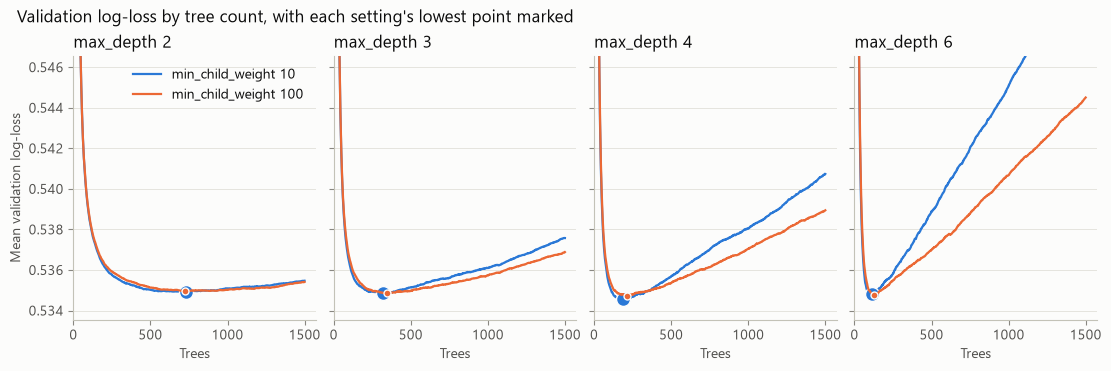

In [5]:
lowest = min(curve.mean(axis=0).min() for curve in curves_by_setting.values())
depths = sorted({depth for depth, _ in curves_by_setting})
figure, axes = plt.subplots(1, len(depths), figsize=(11, 3.6), sharey=True, layout="constrained")
for axis, depth in zip(axes, depths):
    for weight, color, marker_size in ((10, BLUE, 10), (100, ORANGE, 5)):
        mean_curve = curves_by_setting[(depth, weight)].mean(axis=0)
        trees = best_tree_count(curves_by_setting[(depth, weight)])
        axis.plot(np.arange(1, len(mean_curve) + 1), mean_curve, color=color, label=f"min_child_weight {weight}")
        axis.plot(trees, mean_curve[trees - 1], "o", color=color, markersize=marker_size, markeredgecolor=SURFACE, markeredgewidth=1)
    axis.set_title(f"max_depth {depth}")
    axis.set_xlabel("Trees")
    axis.set_xlim(left=0)
axes[0].set_ylim(lowest - 0.001, lowest + 0.012)
axes[0].set_ylabel("Mean validation log-loss")
axes[0].legend(loc="upper right")
figure.suptitle("Validation log-loss by tree count, with each setting's lowest point marked", x=0.01, ha="left", fontsize=12)
figure.savefig(FIGURES / "response_tuning_curves.png", dpi=160)
plt.show()

## 4. Performance

The chosen setting trains in each fold at its locked tree count, then scores that fold's validation rows. These out-of-fold scores are held in memory, for Phase 4's match assertion and for the checks below.

The baseline predicts each training fold's purchase rate for its validation fold. Intervals are stratified percentile bootstraps with 2,000 resamples and seed 42, using the same resamples for the model and the baseline. They capture uncertainty from the evaluation sample, not from refitting the models.

The baseline's interval is almost zero-width by construction. Stratifying on `target` fixes the number of buyers and non-buyers in every resample, and the baseline gives each group nearly the same loss in every fold. That width says nothing about how precisely the baseline is known.

In [6]:
phase3_m1_scores = np.full(len(y), np.nan)
baseline_scores = np.full(len(y), np.nan)
fold_models = {}
fold_rows = []
for fold in FOLDS:
    train, validation = fold_of_row != fold, fold_of_row == fold
    model = XGBClassifier(n_estimators=TREE_COUNT, **FIXED_SETTINGS, **CHOSEN_SETTINGS)
    model.fit(X[train], y[train])
    phase3_m1_scores[validation] = model.predict_proba(X[validation])[:, 1]
    baseline_scores[validation] = y[train].mean()
    fold_models[fold] = model
    fold_rows.append(
        {
            "fold": fold,
            "customers": int(validation.sum()),
            "purchase_rate": y[validation].mean(),
            "auc": roc_auc_score(y[validation], phase3_m1_scores[validation]),
            "log_loss": log_loss(y[validation], phase3_m1_scores[validation]),
            "baseline_log_loss": log_loss(y[validation], baseline_scores[validation]),
        }
    )
assert not np.isnan(phase3_m1_scores).any()

fold_metrics = pd.DataFrame(fold_rows)
# A fit at the locked count must reproduce the tuning curve. The tolerance is tight enough to catch one tree too many or too few.
assert np.allclose(fold_metrics["log_loss"], chosen_row[FOLD_COLUMNS].to_numpy(dtype=float), rtol=0, atol=1e-8)
fold_metrics.to_csv(TABLES / "response_fold_metrics.csv", index=False)
fold_metrics.round(5)

,fold,customers,purchase_rate,auc,log_loss,baseline_log_loss
0,1,15998,0.63652,0.77881,0.53517,0.65540
1,2,15997,0.63649,0.77806,0.53597,0.65541
2,3,15997,0.63649,0.78643,0.52814,0.65541
3,4,15997,0.63649,0.78361,0.53214,0.65541
4,5,15996,0.63653,0.77380,0.54134,0.65539


In [7]:
def row_log_loss(labels, scores):
    assert ((scores > 0) & (scores < 1)).all(), "Scores must lie strictly between 0 and 1"
    return -(labels * np.log(scores) + (1 - labels) * np.log(1 - scores))


def metric_row(name, value, samples):
    low, high = np.percentile(samples, [2.5, 97.5])
    return {"metric": name, "value": value, "ci_low": low, "ci_high": high}


def performance_report(labels, scores, baselines):
    """Pooled AUC and log-loss with stratified bootstrap intervals, using the same resamples for the model and baseline."""
    model_losses = row_log_loss(labels, scores)
    baseline_losses = row_log_loss(labels, baselines)
    _, levels = np.unique(scores, return_inverse=True)
    n_levels = levels.max() + 1
    positives, negatives = np.flatnonzero(labels == 1), np.flatnonzero(labels == 0)

    rng = np.random.default_rng(SEED)
    bootstrap = np.empty((BOOTSTRAP_RESAMPLES, 3))
    for resample in range(BOOTSTRAP_RESAMPLES):
        sampled_positives = rng.choice(positives, size=len(positives))
        sampled_negatives = rng.choice(negatives, size=len(negatives))
        sampled = np.concatenate((sampled_positives, sampled_negatives))
        bootstrap[resample] = (
            auc_from_counts(
                np.bincount(levels[sampled_positives], minlength=n_levels),
                np.bincount(levels[sampled_negatives], minlength=n_levels),
            ),
            model_losses[sampled].mean(),
            baseline_losses[sampled].mean(),
        )

    auc = roc_auc_score(labels, scores)
    loss = log_loss(labels, scores)
    baseline_loss = log_loss(labels, baselines)
    assert np.isclose(loss, model_losses.mean()) and np.isclose(baseline_loss, baseline_losses.mean())
    assert np.isclose(auc, auc_from_counts(np.bincount(levels[positives], minlength=n_levels), np.bincount(levels[negatives], minlength=n_levels)))

    table = pd.DataFrame(
        [
            metric_row("AUC", auc, bootstrap[:, 0]),
            metric_row("Log-loss", loss, bootstrap[:, 1]),
            metric_row("Baseline log-loss", baseline_loss, bootstrap[:, 2]),
            metric_row("Log-loss minus baseline", loss - baseline_loss, bootstrap[:, 1] - bootstrap[:, 2]),
        ]
    )
    return table, auc, loss, baseline_loss


metrics, overall_auc, overall_log_loss, overall_baseline_log_loss = performance_report(y, phase3_m1_scores, baseline_scores)
metrics.to_csv(TABLES / "response_metrics.csv", index=False)
metrics.round(5)

,metric,value,ci_low,ci_high
0,AUC,0.78008,0.77691,0.78322
1,Log-loss,0.53455,0.53168,0.53746
2,Baseline log-loss,0.65540,0.65540,0.65540
3,Log-loss minus baseline,-0.12085,-0.12372,-0.11794


## 5. Calibration

Ten equal-count bins of the out-of-fold scores, plus a slope and intercept fitted together by logistic regression of `target` on the logit of the score. A flag is reported and the work proceeds without recalibrating, unless the project owner decides otherwise. Recalibrating would not change the response ranking, but it would change `tau(X) = m1(X) - m0(X)`.

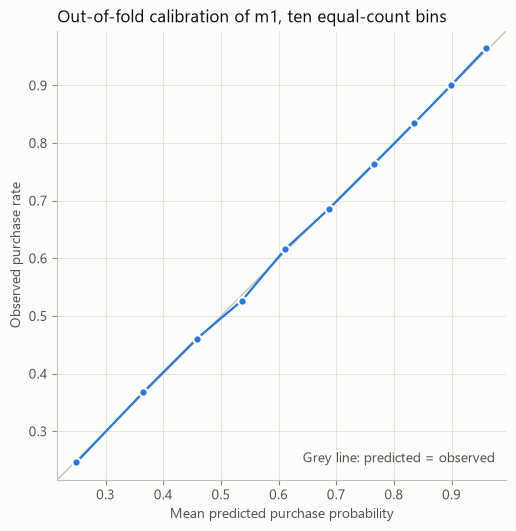

Slope 1.0067, intercept -0.0036


,bin,customers,mean_predicted,observed_rate,gap_points
0,1,7999,0.2493,0.2463,-0.3059
1,2,7998,0.3656,0.3681,0.2475
2,3,7999,0.4580,0.4604,0.2390
3,4,7998,0.5364,0.5268,-0.9602
4,5,7999,0.6116,0.6162,0.4641
5,6,7998,0.6867,0.6853,-0.1453
6,7,7998,0.7646,0.7629,-0.1642
7,8,7999,0.8353,0.8344,-0.0917
8,9,7998,0.8989,0.8998,0.0959
9,10,7999,0.9605,0.9649,0.4346


In [8]:
def calibration_report(labels, scores):
    assert ((scores > 0) & (scores < 1)).all(), "Scores must lie strictly between 0 and 1"
    bins = pd.qcut(pd.Series(scores).rank(method="first"), 10, labels=False) + 1
    table = (
        pd.DataFrame({"bin": bins, "label": labels, "score": scores})
        .groupby("bin")
        .agg(customers=("label", "size"), mean_predicted=("score", "mean"), observed_rate=("label", "mean"))
        .reset_index()
    )
    table["gap_points"] = (table["observed_rate"] - table["mean_predicted"]) * 100
    fit = sm.Logit(labels, sm.add_constant(np.log(scores / (1 - scores)))).fit(disp=0)
    return table, float(fit.params[0]), float(fit.params[1])


def plot_calibration(table, title, path):
    figure, axis = plt.subplots(figsize=(5.6, 5.2), layout="constrained")
    limits = (table[["mean_predicted", "observed_rate"]].min().min() - 0.03, table[["mean_predicted", "observed_rate"]].max().max() + 0.03)
    axis.plot(limits, limits, color=AXIS, linewidth=1)
    axis.text(limits[1] - 0.02, limits[0] + 0.03, "Grey line: predicted = observed", ha="right", color=INK_SECONDARY)
    axis.plot(table["mean_predicted"], table["observed_rate"], "-o", color=BLUE, markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
    axis.set_xlim(limits)
    axis.set_ylim(limits)
    axis.set_aspect("equal")
    axis.grid(True, axis="both")
    axis.set_xlabel("Mean predicted purchase probability")
    axis.set_ylabel("Observed purchase rate")
    axis.set_title(title)
    figure.savefig(path, dpi=160)
    plt.show()


calibration, calibration_intercept, calibration_slope = calibration_report(y, phase3_m1_scores)
calibration.to_csv(TABLES / "response_calibration.csv", index=False)
pd.DataFrame([{"intercept": calibration_intercept, "slope": calibration_slope}]).to_csv(TABLES / "response_calibration_summary.csv", index=False)
plot_calibration(calibration, "Out-of-fold calibration of m1, ten equal-count bins", FIGURES / "response_calibration.png")

print(f"Slope {calibration_slope:.4f}, intercept {calibration_intercept:.4f}")
calibration.round(4)

## 6. Leakage review

Gain share is each feature's share of total gain in each fold model, averaged across the five models. Single-feature AUC is `max(AUC, 1 - AUC)`, leaving out rows where the feature is null. Strong recency effects are expected and do not show leakage on their own.

In [9]:
def gain_shares(model):
    gains = model.get_booster().get_score(importance_type="total_gain")
    values = np.array([gains.get(f"f{j}", 0.0) for j in range(len(FEATURE_NAMES))])
    assert values.sum() > 0
    return values / values.sum()


def single_feature_auc(values, labels):
    present = ~np.isnan(values)
    auc = roc_auc_score(labels[present], values[present])
    return max(auc, 1 - auc)


def feature_importance_table(models_by_fold, rows, labels):
    shares_by_fold = np.array([gain_shares(models_by_fold[fold]) for fold in FOLDS])
    return pd.DataFrame(
        {
            "feature": FEATURE_NAMES,
            "gain_share": shares_by_fold.mean(axis=0),
            "lowest_fold_share": shares_by_fold.min(axis=0),
            "highest_fold_share": shares_by_fold.max(axis=0),
            "single_feature_auc": [single_feature_auc(rows[:, j], labels) for j in range(len(FEATURE_NAMES))],
        }
    ).sort_values("gain_share", ascending=False)


importance = feature_importance_table(fold_models, X, y)
importance.to_csv(TABLES / "response_feature_importance.csv", index=False)
importance.round(4)

,feature,gain_share,lowest_fold_share,highest_fold_share,single_feature_auc
6,txn_count_60d,0.2779,0.2609,0.2924,0.7552
8,active_days_hist,0.1664,0.1420,0.1858,0.7517
5,txn_count_30d,0.1621,0.1525,0.1770,0.7486
9,avg_gap_days,0.0827,0.0778,0.0891,0.7392
0,days_since_last_purchase,0.0771,0.0690,0.0823,0.6996
7,txn_count_90d,0.0567,0.0404,0.0736,0.7527
4,txn_count_14d,0.0268,0.0247,0.0307,0.7240
32,age,0.0179,0.0162,0.0195,0.5417
3,txn_count_7d,0.0148,0.0132,0.0175,0.6984
2,txn_count_hist,0.0136,0.0088,0.0191,0.7498


### Purchase rate by recency

This check is descriptive and has no automatic rule. A smooth decline looks like habit, while a sharp jump at 0 or 1 days would suggest the undocumented outcome window overlaps the end of the purchase history. The project owner reviews it before Phase 4. The shaded band is a 95% Wald interval.

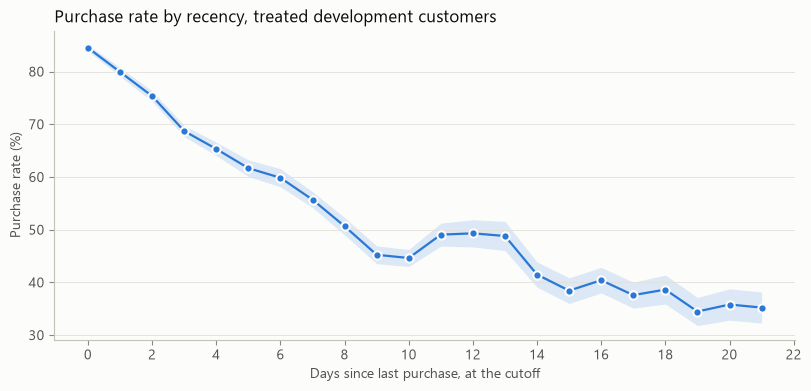

,days_since_last_purchase,customers,purchase_rate,ci_low,ci_high
0,0,14165,0.8450,0.8390,0.8509
1,1,8752,0.7992,0.7909,0.8076
2,2,7423,0.7535,0.7437,0.7633
3,3,7335,0.6871,0.6765,0.6977
4,4,5429,0.6532,0.6405,0.6658
5,5,3650,0.6167,0.6009,0.6325
6,6,3113,0.5985,0.5812,0.6157
7,7,4187,0.5570,0.5419,0.5720
8,8,3585,0.5066,0.4902,0.5229
9,9,3307,0.4524,0.4354,0.4693


In [10]:
recency = (
    customers.groupby("days_since_last_purchase")["target"]
    .agg(customers="size", purchase_rate="mean")
    .reset_index()
)
assert recency["days_since_last_purchase"].between(0, 22).all() and recency["customers"].sum() == len(y)
margin = 1.96 * np.sqrt(recency["purchase_rate"] * (1 - recency["purchase_rate"]) / recency["customers"])
recency["ci_low"], recency["ci_high"] = recency["purchase_rate"] - margin, recency["purchase_rate"] + margin
recency.to_csv(TABLES / "response_recency.csv", index=False)

figure, axis = plt.subplots(figsize=(8, 3.8), layout="constrained")
axis.fill_between(recency["days_since_last_purchase"], recency["ci_low"] * 100, recency["ci_high"] * 100, color=BLUE, alpha=0.15, linewidth=0)
axis.plot(recency["days_since_last_purchase"], recency["purchase_rate"] * 100, "-o", color=BLUE, markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
axis.set_xlabel("Days since last purchase, at the cutoff")
axis.set_ylabel("Purchase rate (%)")
axis.set_xticks(range(0, 23, 2))
axis.set_title("Purchase rate by recency, treated development customers")
figure.savefig(FIGURES / "response_recency.png", dpi=160)
plt.show()

recency.round(4)

## 7. Applying the committed rules

Every table above is written first, so a stop still leaves its evidence on disk. The locked setup file is written only if no stop rule triggers. Calibration flags do not stop the notebook.

In [11]:
largest_gain = importance.iloc[0]
largest_single_auc = importance.sort_values("single_feature_auc", ascending=False).iloc[0]
largest_bin_gap = calibration["gap_points"].abs().max()

decision = pd.DataFrame(
    [
        ("Log-loss below baseline", f"{overall_log_loss:.5f} vs {overall_baseline_log_loss:.5f}", "Stop if not below", overall_log_loss >= overall_baseline_log_loss, "Stop"),
        (f"Largest gain share ({largest_gain['feature']})", f"{largest_gain['gain_share']:.4f}", f">= {GAIN_STOP}", largest_gain["gain_share"] >= GAIN_STOP, "Stop"),
        (f"Largest single-feature AUC ({largest_single_auc['feature']})", f"{largest_single_auc['single_feature_auc']:.4f}", f">= {SINGLE_FEATURE_AUC_STOP}", largest_single_auc["single_feature_auc"] >= SINGLE_FEATURE_AUC_STOP, "Stop"),
        ("Overall out-of-fold AUC", f"{overall_auc:.4f}", f">= {OVERALL_AUC_STOP}", overall_auc >= OVERALL_AUC_STOP, "Stop"),
        ("Calibration slope", f"{calibration_slope:.4f}", f"Outside {SLOPE_RANGE[0]} to {SLOPE_RANGE[1]}", not SLOPE_RANGE[0] <= calibration_slope <= SLOPE_RANGE[1], "Report and proceed"),
        ("Largest calibration bin gap (points)", f"{largest_bin_gap:.2f}", f"> {BIN_GAP_FLAG_POINTS}", largest_bin_gap > BIN_GAP_FLAG_POINTS, "Report and proceed"),
    ],
    columns=["check", "measured", "threshold", "triggered", "action_if_triggered"],
)
decision.to_csv(TABLES / "response_decision.csv", index=False)
display(decision)

stops = decision[decision["triggered"] & (decision["action_if_triggered"] == "Stop")]
if len(stops):
    raise RuntimeError("Stop and investigate before Phase 4: " + "; ".join(stops["check"]))
setup = {**FIXED_SETTINGS, **CHOSEN_SETTINGS, "n_estimators": TREE_COUNT}
pd.Series(setup, name="value").rename_axis("setting").reset_index().to_csv(TABLES / "response_model_setup.csv", index=False)
print("No stop rule triggered. Locked setup:", setup)

,check,measured,threshold,triggered,action_if_triggered
0,Log-loss below baseline,0.53455 vs 0.65540,Stop if not below,False,Stop
1,Largest gain share (txn_count_60d),0.2779,>= 0.5,False,Stop
2,Largest single-feature AUC (txn_count_60d),0.7552,>= 0.8,False,Stop
3,Overall out-of-fold AUC,0.7801,>= 0.9,False,Stop
4,Calibration slope,1.0067,Outside 0.9 to 1.1,False,Report and proceed
5,Largest calibration bin gap (points),0.96,> 2.0,False,Report and proceed


No stop rule triggered. Locked setup: {'objective': 'binary:logistic', 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'tree_method': 'hist', 'random_state': 42, 'reg_lambda': 1, 'reg_alpha': 0, 'gamma': 0, 'n_jobs': 8, 'max_depth': 4, 'min_child_weight': 10, 'n_estimators': 185}


### Measurements quoted in the documents

The conclusion below and `reports/decisions.md` quote these values, so a change must stop the run.

In [12]:
assert CHOSEN_SETTINGS == {"max_depth": 4, "min_child_weight": 10} and TREE_COUNT == 185
assert tuning["eligible"].sum() == 1 and tuning.loc[tuning["eligible"], "best"].all()
assert tuning["tree_cap_used"].eq(FIRST_TREE_CAP).all()
assert tuning[["max_depth", "min_child_weight", "tree_count"]].to_numpy().tolist() == [
    [2, 10, 730], [2, 100, 726], [3, 10, 320], [3, 100, 345], [4, 10, 185], [4, 100, 214], [6, 10, 113], [6, 100, 126],
]
assert tuning["mean_log_loss"].round(5).tolist() == [0.53492, 0.53496, 0.53485, 0.53485, 0.53455, 0.53473, 0.53480, 0.53477]
assert metrics[["value", "ci_low", "ci_high"]].round(4).to_numpy().tolist() == [
    [0.7801, 0.7769, 0.7832],
    [0.5346, 0.5317, 0.5375],
    [0.6554, 0.6554, 0.6554],
    [-0.1209, -0.1237, -0.1179],
]
assert round(calibration_slope, 4) == 1.0067 and round(calibration_intercept, 4) == -0.0036
assert round(largest_bin_gap, 2) == 0.96
assert (largest_gain["feature"], round(largest_gain["gain_share"], 4)) == ("txn_count_60d", 0.2779)
assert (largest_single_auc["feature"], round(largest_single_auc["single_feature_auc"], 4)) == ("txn_count_60d", 0.7552)
assert recency["days_since_last_purchase"].tolist() == list(range(22))
quoted_days = recency.set_index("days_since_last_purchase").loc[[0, 1, 2, 3, 10, 11, 12, 13, 14]]
assert quoted_days["customers"].tolist() == [14_165, 8_752, 7_423, 7_335, 3_666, 2_016, 1_448, 1_254, 1_632]
assert (quoted_days["purchase_rate"] * 100).round(1).tolist() == [84.5, 79.9, 75.3, 68.7, 44.6, 49.1, 49.3, 48.8, 41.5]
assert (quoted_days["ci_low"] * 100).round(1).tolist() == [83.9, 79.1, 74.4, 67.7, 43.0, 46.9, 46.7, 46.0, 39.1]
assert (quoted_days["ci_high"] * 100).round(1).tolist() == [85.1, 80.8, 76.3, 69.8, 46.2, 51.2, 51.9, 51.6, 43.9]
assert tuning["mean_difference"].round(5).tolist() == [0.00037, 0.00041, 0.00030, 0.00030, 0.0, 0.00018, 0.00025, 0.00022]
assert tuning["se_difference"].round(5).tolist() == [0.00012, 0.00014, 0.00011, 0.00014, 0.0, 0.00015, 0.00019, 0.00016]
assert (round(fold_metrics["auc"].min(), 4), round(fold_metrics["auc"].max(), 4)) == (0.7738, 0.7864)
express = importance[importance["feature"].str.startswith("express_")]
assert (round(express["gain_share"].max(), 4), round(express["single_feature_auc"].max(), 4)) == (0.0079, 0.5144)
assert calibration.loc[calibration["gap_points"].abs().idxmax(), "bin"] == 4
tenth_bin = calibration[calibration["bin"] == 10].iloc[0]
assert (round(tenth_bin["mean_predicted"] * 100, 1), round(tenth_bin["observed_rate"] * 100, 1)) == (96.1, 96.5)
print("All quoted values match")

All quoted values match


## Phase 3 conclusion

All values are **Measured** on out-of-fold predictions for the 79,985 treated development customers.

- **Locked setup:** `max_depth` 4, `min_child_weight` 10 and 185 trees, with the fixed settings in `outputs/tables/response_model_setup.csv`. It was the only setting within one standard error of the best, because it was the best. The eight settings differ by at most 0.0004 in mean log-loss.
- **Performance:** AUC 0.7801 (95% CI 0.7769 to 0.7832) and log-loss 0.5346 (0.5317 to 0.5375), against a baseline log-loss of 0.6554.
- **Calibration:** slope 1.0067, intercept -0.0036, largest bin gap 0.96 points. Neither flag was raised, so nothing was recalibrated.
- **Leakage thresholds:** none reached. The largest gain share and single-feature AUC are both `txn_count_60d`, at 0.2779 and 0.7552, and overall AUC is below 0.90.
- **Recency:** the purchase rate falls from 84.5% at 0 days through 79.9%, 75.3% and 68.7% at 3 days, with no sharp jump at 0 or 1 days. An unexplained step up at 11 to 13 days is about 49%, against 44.6% at 10 days and 41.5% at 14 days. No treated development customer has a value of 22.

**What this does not show:** these metrics describe how well the model predicts purchase among treated customers. They say nothing about whether the SMS changed anyone's behaviour, which Phases 4 and 5 address.

# Phase 4: T-Learner

**Goal:** build `m0(X) = P(target = 1 given X, treatment_flg = 0)`, the uplift score `tau(X) = m1(X) - m0(X)`, and scores for every labelled customer from models that did not train on them.

The rules were committed in `reports/decisions.md` before these cells first ran. Holdout scoring reads features only. This phase never compares `tau` with `target`, so it says nothing about whether uplift targeting works.

An individual `tau(X)` is **Estimated from the model**. It is not a measured effect on that customer, and a negative score does not show that the SMS harmed anyone.

## 8. Known-answer checks on the shared code

Top-K selection, arm balance and the holdout freeze live in `notebooks/targeting.py`, because a later notebook must apply them identically. Every result here must match a value worked out by hand.

In [13]:
def rejected(call):
    try:
        call()
    except ValueError:
        return True
    return False


def as_32_bit(*values):
    return np.array(values, dtype=np.float32)


# Top-K selection: highest scores first, ties by client_id, whatever the input order.
assert select_top_k(["a", "b", "c", "d", "e"], [0.1, 0.5, 0.3, 0.4, 0.2], 40).tolist() == [False, True, False, True, False]
assert select_top_k(["d", "b", "a", "c"], [0.5, 0.5, 0.5, 0.5], 50).tolist() == [False, True, True, False]
assert select_top_k(["a", "b", "c", "d"], [-0.2, -0.1, 0.1, -0.3], 50).tolist() == [False, True, True, False]

# Group sizes, including the two quoted in the log and exact halves rounding up.
for customers_in_group, percent, size in ((160_031, 20, 32_006), (40_008, 20, 8_002), (10, 25, 3), (30, 5, 2), (50, 5, 3), (3, 100, 3)):
    assert select_by_rank(np.arange(customers_in_group), percent).sum() == size

# A bootstrap resample repeats customers and selects on resampled ranks.
known_ranks = score_ranks(["a", "b", "c", "d"], [0.4, 0.3, 0.2, 0.1])
assert known_ranks.tolist() == [0, 1, 2, 3]
assert select_by_rank(known_ranks[[3, 0, 0, 1, 2]], 40).tolist() == [False, True, True, False, False]

# Bad inputs stop.
for bad_call in (
    lambda: select_top_k(["a", "a"], [0.1, 0.2], 50),
    lambda: select_top_k([9, 10, 11], [1.0, 1.0, 1.0], 34),
    lambda: select_top_k([None, "b"], [0.1, 0.2], 50),
    lambda: select_top_k(["a", "b"], [0.1, np.nan], 50),
    lambda: select_top_k(["a", "b"], [np.inf, 0.2], 50),
    lambda: select_top_k(["a", "b"], ["0.1", "0.2"], 50),
    lambda: select_top_k(["a", "b"], [True, False], 50),
    lambda: select_top_k(["a", "b"], [0.1, 0.2], 0.2),
    lambda: select_top_k(["a", "b"], [0.1, 0.2], 1),
    lambda: select_by_rank([0.9, 0.1, 0.5], 34),
    lambda: select_by_rank([-1, 1, 2], 34),
):
    assert rejected(bad_call)

# Arm balance. Treated 2 and 4, control 1 and 3: means 3 and 2, variances 2 and 2, so SMD = 1 / sqrt(2).
known_balance = arm_balance(["a", "b", "c", "d"], [1, 1, 0, 0], [2.0, 4.0, 1.0, 3.0])
assert np.isclose(known_balance["smd"], 1 / np.sqrt(2)) and np.isclose(known_balance["sd_ratio"], 1.0)
assert known_balance["treated_share_top_20"] == 1.0
# Treated 1 and 3, control 0, 4 and 2: means match, SDs sqrt(2) and 2, and the top customer is control.
known_balance = arm_balance(["a", "b", "c", "d", "e"], [1, 1, 0, 0, 0], [1.0, 3.0, 0.0, 4.0, 2.0])
assert np.isclose(known_balance["smd"], 0.0) and np.isclose(known_balance["sd_ratio"], np.sqrt(2) / 2)
assert known_balance["treated_share_top_20"] == 0.0
assert rejected(lambda: arm_balance(["a", "b", "c", "d"], [1, 1, 0, 0], [1.0, 1.0, 1.0, 1.0]))
assert rejected(lambda: arm_balance(["a", "b", "c", "d"], [1, 1, 0, 0], ["1.0", "3.0", "0.0", "4.0"]))
assert rejected(lambda: arm_balance(["a", "b", "c"], [1, 0, 0], [1.0, 2.0, 3.0]))

# The hash follows the logged format: 1.0 = 3f800000, 0.5 = 3f000000, 0.25 = 3e800000, -2.0 = c0000000.
known_hash = hashlib.sha256(b"a,3f800000,3e800000\nb,3f000000,c0000000\n").hexdigest()
assert holdout_score_hash(["a", "b"], as_32_bit(1.0, 0.5), as_32_bit(0.25, -2.0)) == known_hash
assert rejected(lambda: holdout_score_hash(["a", "b"], np.array([1.0, 0.5]), as_32_bit(0.25, -2.0)))
assert rejected(lambda: holdout_score_hash(["b", "a"], as_32_bit(1.0, 0.5), as_32_bit(0.25, -2.0)))

# tau is the exact 64-bit difference, not a 32-bit one.
known_high, known_low = as_32_bit(0.30000001), as_32_bit(0.1)
known_tau = known_high.astype(np.float64) - known_low.astype(np.float64)
assert_exact_tau(known_high, known_low, known_tau)
assert rejected(lambda: assert_exact_tau(known_high, known_low, (known_high - known_low).astype(np.float64)))
assert rejected(lambda: assert_exact_tau(known_low, known_high, known_tau))

# Every freeze state, in the order the log tests them.
known_ids, known_m1, known_m0 = ["a", "b"], as_32_bit(0.5, 0.25), as_32_bit(0.125, 0.75)
good_hash = holdout_score_hash(known_ids, known_m1, known_m0)
known_reference = pd.DataFrame({"m1_score": [0.5, 0.25], "m0_score": [0.125, 0.75]})


def known_freeze(recorded, reference, m1_scores=known_m1, m0_scores=known_m0, first_run_allowed=True, client_ids=known_ids, expected_ids=known_ids):
    return check_freeze(recorded, reference, client_ids, expected_ids, m1_scores, m0_scores, first_run_allowed)[0]


assert known_freeze(good_hash, known_reference, client_ids=["a", "c"]) == "stop"
assert known_freeze(good_hash, known_reference, client_ids=["b", "a"], expected_ids=["b", "a"]) == "stop"
assert known_freeze(None, None) == "first_run"
assert known_freeze(None, None, first_run_allowed=False) == "stop"
assert known_freeze(None, known_reference) == "stop"
assert known_freeze(good_hash, None) == "stop"
assert known_freeze(good_hash, known_reference.iloc[:1]) == "stop"
assert known_freeze(good_hash, known_reference) == "proceed"
assert known_freeze("0" * 64, known_reference) == "warn"
assert known_freeze("0" * 64, known_reference, m1_scores=as_32_bit(0.5 + 9e-6, 0.25)) == "warn"
assert known_freeze("0" * 64, known_reference, m1_scores=as_32_bit(0.5 + 2e-5, 0.25)) == "stop"
assert known_freeze("0" * 64, known_reference, m0_scores=as_32_bit(0.125 + 9e-6, 0.75)) == "warn"
assert known_freeze("0" * 64, known_reference, m0_scores=as_32_bit(0.125 + 2e-5, 0.75)) == "stop"
assert known_freeze("0" * 64, known_reference.assign(m1_score=[np.nan, 0.25])) == "stop"
# A stale hash cannot pass, because the hash comes from the scores passed in.
assert known_freeze(good_hash, known_reference, m1_scores=as_32_bit(0.5 + 2e-5, 0.25)) == "stop"
assert rejected(lambda: known_freeze(good_hash, known_reference, m1_scores=as_32_bit(0.5)))

print("All known-answer checks on the shared code passed")

All known-answer checks on the shared code passed


## 9. Load development and holdout customers

Phase 3 is finished by this point, so development labels can now load for both arms. The holdout query reads `customer_features.parquet` and `splits.parquet` only, and never touches the label file. The Phase 3 cells have already checked the split against its recorded hash.

In [14]:
EXPECTED_DEVELOPMENT = 160_031
EXPECTED_CONTROL_FOLD_SIZES = {1: 16_009, 2: 16_009, 3: 16_009, 4: 16_009, 5: 16_010}
ALL_CUSTOMERS = 200_039

SMD_STOP = 0.05
SD_RATIO_RANGE = (0.9, 1.1)
TREATED_SHARE_RANGE = (0.48, 0.52)
FOLD_SHARE_FLAG_RANGE = (0.15, 0.25)
MATCH_TOLERANCE = 1e-9

SCORES_OOF_PATH = PROCESSED / "scores_oof.parquet"
SCORES_HOLDOUT_PATH = PROCESSED / "scores_holdout.parquet"
MODELS = Path("models")
M1_MODEL_PATH, M0_MODEL_PATH = MODELS / "m1_refit.ubj", MODELS / "m0_refit.ubj"
REFERENCE_PATH = TABLES / "holdout_scores_reference.csv"
STAGING = PROCESSED / "phase4_staging"

# Phase 3's objects are no longer needed, apart from its scores for the match below.
phase3_client_ids = customers["client_id"].tolist()
del customers, fold_models, curves_by_setting

con = duckdb.connect()
development = query(
    f"""
    SELECT f.*, s.fold, l.treatment_flg, l.target
    FROM '{FEATURES_PATH}' AS f
    JOIN '{SPLITS_PATH}' AS s USING (client_id)
    JOIN '{LABELS_PATH}' AS l USING (client_id)
    WHERE s.split = 'development'
    ORDER BY f.client_id
    """
)
holdout = query(
    f"""
    SELECT f.*
    FROM '{FEATURES_PATH}' AS f
    JOIN '{SPLITS_PATH}' AS s USING (client_id)
    WHERE s.split = 'holdout'
    ORDER BY f.client_id
    """
)
expected_holdout_ids = query(f"SELECT client_id FROM '{SPLITS_PATH}' WHERE split = 'holdout' ORDER BY client_id")["client_id"].tolist()
all_split_ids = set(query(f"SELECT client_id FROM '{SPLITS_PATH}'")["client_id"])
con.close()

assert len(development) == EXPECTED_DEVELOPMENT and len(holdout) == EXPECTED_HOLDOUT and len(all_split_ids) == ALL_CUSTOMERS
assert development["client_id"].is_unique and development["client_id"].is_monotonic_increasing
assert holdout["client_id"].is_unique and holdout["client_id"].is_monotonic_increasing
assert set(development["client_id"]).isdisjoint(holdout["client_id"])
assert holdout.columns.tolist() == ["client_id", *FEATURE_NAMES], "Holdout scoring must read features only"
assert holdout["client_id"].tolist() == expected_holdout_ids
assert development["target"].isin([0, 1]).all() and development["treatment_flg"].isin([0, 1]).all()

client_ids_dev = development["client_id"].tolist()
client_ids_holdout = holdout["client_id"].tolist()
X_dev = development[FEATURE_NAMES].to_numpy(dtype=float, na_value=np.nan)
y_dev = development["target"].to_numpy(dtype=int)
treatment_dev = development["treatment_flg"].to_numpy(dtype=int)
fold_dev = development["fold"].to_numpy(dtype=int)
X_holdout = holdout[FEATURE_NAMES].to_numpy(dtype=float, na_value=np.nan)
treated, control = treatment_dev == 1, treatment_dev == 0

assert treated.sum() == EXPECTED_TREATED_DEVELOPMENT
assert pd.Series(fold_dev[treated]).value_counts().sort_index().to_dict() == EXPECTED_FOLD_SIZES
assert pd.Series(fold_dev[control]).value_counts().sort_index().to_dict() == EXPECTED_CONTROL_FOLD_SIZES

# The treated rows must be Phase 3's rows, in Phase 3's order, because training row order changes the fitted model.
assert development.loc[treated, "client_id"].tolist() == phase3_client_ids
assert np.array_equal(X_dev[treated], X, equal_nan=True) and np.array_equal(y_dev[treated], y) and np.array_equal(fold_dev[treated], fold_of_row)
del development, holdout, phase3_client_ids

print(f"{treated.sum():,} treated and {control.sum():,} control development customers, {len(X_holdout):,} holdout customers")

79,985 treated and 80,046 control development customers, 40,008 holdout customers


### Development interval for the mean `tau` check

The unpooled Wald 95% interval for the treated-minus-control purchase rate difference, using the Phase 1 method on development rows only. No holdout outcome enters it.

In [15]:
development_difference = y_dev[treated].mean() - y_dev[control].mean()
development_se = np.sqrt(
    y_dev[treated].mean() * (1 - y_dev[treated].mean()) / treated.sum()
    + y_dev[control].mean() * (1 - y_dev[control].mean()) / control.sum()
)
Z_95 = stats.norm.ppf(0.975)
development_interval = (development_difference - Z_95 * development_se, development_difference + Z_95 * development_se)
pd.DataFrame(
    [
        {
            "treated_rate": y_dev[treated].mean(),
            "control_rate": y_dev[control].mean(),
            "difference": development_difference,
            "ci_low": development_interval[0],
            "ci_high": development_interval[1],
        }
    ]
).to_csv(TABLES / "uplift_development_interval.csv", index=False)
print(f"Development difference {development_difference * 100:+.2f} points, 95% CI {development_interval[0] * 100:+.2f} to {development_interval[1] * 100:+.2f}")

Development difference +3.32 points, 95% CI +2.85 to +3.80


## 10. Out-of-fold scores

In each fold, `m1` trains on the treated training rows and `m0` on the control training rows, both with the setup locked in Phase 3. Each then scores every validation row in both arms, because evaluating a target group compares treated and control customers inside it.

In [16]:
def new_model():
    return XGBClassifier(n_estimators=TREE_COUNT, **FIXED_SETTINGS, **CHOSEN_SETTINGS)


def fit_for_fold(arm_rows, arm_fold_sizes, fold):
    """Train on one arm's rows outside `fold`. Every fold model trains here, so these checks cover what it actually saw."""
    training_rows = np.flatnonzero(arm_rows & (fold_dev != fold))
    assert (fold_dev[training_rows] != fold).all(), "A model must not train on the fold it scores"
    assert set(treatment_dev[training_rows].tolist()) == set(treatment_dev[arm_rows].tolist()), "A model must train on one arm only"
    assert len(training_rows) == sum(arm_fold_sizes.values()) - arm_fold_sizes[fold]
    assert set(np.asarray(client_ids_dev, dtype=object)[training_rows]).isdisjoint(np.asarray(client_ids_dev, dtype=object)[fold_dev == fold])
    return new_model().fit(X_dev[training_rows], y_dev[training_rows])


m1_oof = np.full(len(y_dev), np.nan, dtype=np.float32)
m0_oof = np.full(len(y_dev), np.nan, dtype=np.float32)
m0_baseline = np.full(len(y_dev), np.nan)
times_scored = np.zeros(len(y_dev), dtype=int)
m1_fold_models, m0_fold_models = {}, {}

for fold in FOLDS:
    validation = fold_dev == fold
    m1_fold_models[fold] = fit_for_fold(treated, EXPECTED_FOLD_SIZES, fold)
    m0_fold_models[fold] = fit_for_fold(control, EXPECTED_CONTROL_FOLD_SIZES, fold)

    m1_oof[validation] = m1_fold_models[fold].predict_proba(X_dev[validation])[:, 1]
    m0_oof[validation] = m0_fold_models[fold].predict_proba(X_dev[validation])[:, 1]
    m0_baseline[validation] = y_dev[control & (fold_dev != fold)].mean()
    times_scored[validation] += 1

# Each row is scored once, in its own fold, by models that fit_for_fold kept away from that fold.
assert (times_scored == 1).all()
assert not np.isnan(m1_oof).any() and not np.isnan(m0_oof).any()

m1_match_gap = np.abs(m1_oof[treated].astype(np.float64) - phase3_m1_scores).max()
assert m1_match_gap <= MATCH_TOLERANCE, f"m1 differs from Phase 3 by {m1_match_gap}"
print(f"Largest m1 difference from Phase 3 on treated rows: {m1_match_gap}")
del X, y, fold_of_row, phase3_m1_scores

Largest m1 difference from Phase 3 on treated rows: 0.0


## 11. Checks on `m0`

The same reports and thresholds as `m1`, on the 80,046 control development customers. A calibration flag is reported, with no recalibration, because that would change `tau`. These metrics describe prediction of purchase among control customers, not the effect of the SMS.

In [17]:
y_control = y_dev[control]
m0_control_scores = m0_oof[control].astype(np.float64)
m0_control_baseline = m0_baseline[control]
fold_control = fold_dev[control]

m0_fold_metrics = pd.DataFrame(
    [
        {
            "fold": fold,
            "customers": int((fold_control == fold).sum()),
            "purchase_rate": y_control[fold_control == fold].mean(),
            "auc": roc_auc_score(y_control[fold_control == fold], m0_control_scores[fold_control == fold]),
            "log_loss": log_loss(y_control[fold_control == fold], m0_control_scores[fold_control == fold]),
            "baseline_log_loss": log_loss(y_control[fold_control == fold], m0_control_baseline[fold_control == fold]),
        }
        for fold in FOLDS
    ]
)
m0_fold_metrics.to_csv(TABLES / "m0_fold_metrics.csv", index=False)

m0_metrics, m0_auc, m0_log_loss, m0_baseline_log_loss = performance_report(y_control, m0_control_scores, m0_control_baseline)
m0_metrics.to_csv(TABLES / "m0_metrics.csv", index=False)
display(m0_fold_metrics.round(5), m0_metrics.round(5))

,fold,customers,purchase_rate,auc,log_loss,baseline_log_loss
0,1,16009,0.60329,0.77788,0.54830,0.67166
1,2,16009,0.60329,0.78634,0.54080,0.67166
2,3,16009,0.60329,0.78408,0.54239,0.67166
3,4,16009,0.60329,0.78176,0.54548,0.67166
4,5,16010,0.60325,0.77856,0.54896,0.67167


,metric,value,ci_low,ci_high
0,AUC,0.78166,0.77843,0.78479
1,Log-loss,0.54519,0.54226,0.54825
2,Baseline log-loss,0.67166,0.67166,0.67166
3,Log-loss minus baseline,-0.12647,-0.12940,-0.12341


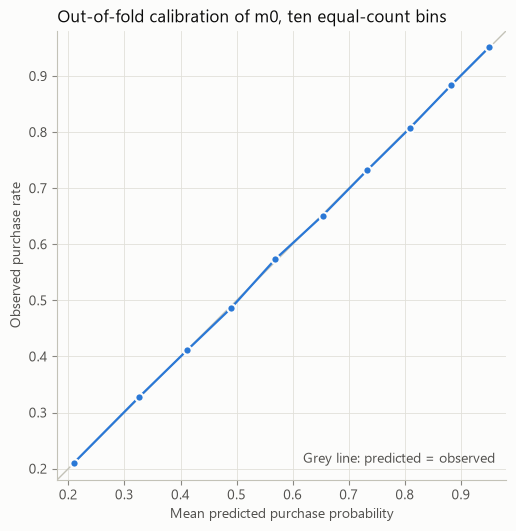

Slope 1.0007, intercept -0.0007


,bin,customers,mean_predicted,observed_rate,gap_points
0,1,8005,0.2105,0.2109,0.0402
1,2,8005,0.3259,0.3274,0.1514
2,3,8004,0.4117,0.4110,-0.0686
3,4,8005,0.4904,0.4864,-0.3946
4,5,8004,0.5686,0.5731,0.4533
5,6,8005,0.6532,0.6510,-0.2226
6,7,8004,0.7330,0.7321,-0.0883
7,8,8005,0.8084,0.8065,-0.1865
8,9,8004,0.8825,0.8836,0.1071
9,10,8005,0.9496,0.9508,0.1134


In [18]:
m0_calibration, m0_calibration_intercept, m0_calibration_slope = calibration_report(y_control, m0_control_scores)
m0_calibration.to_csv(TABLES / "m0_calibration.csv", index=False)
pd.DataFrame([{"intercept": m0_calibration_intercept, "slope": m0_calibration_slope}]).to_csv(TABLES / "m0_calibration_summary.csv", index=False)
plot_calibration(m0_calibration, "Out-of-fold calibration of m0, ten equal-count bins", FIGURES / "m0_calibration.png")

print(f"Slope {m0_calibration_slope:.4f}, intercept {m0_calibration_intercept:.4f}")
m0_calibration.round(4)

In [19]:
m0_importance = feature_importance_table(m0_fold_models, X_dev[control], y_control)
m0_importance.to_csv(TABLES / "m0_feature_importance.csv", index=False)
m0_importance.round(4).head(12)

,feature,gain_share,lowest_fold_share,highest_fold_share,single_feature_auc
6,txn_count_60d,0.2950,0.2352,0.3340,0.7621
8,active_days_hist,0.1856,0.1677,0.2194,0.7583
5,txn_count_30d,0.1346,0.1182,0.1657,0.7542
7,txn_count_90d,0.1155,0.0966,0.1316,0.7605
9,avg_gap_days,0.0570,0.0494,0.0634,0.7421
0,days_since_last_purchase,0.0561,0.0548,0.0572,0.6990
4,txn_count_14d,0.0312,0.0275,0.0365,0.7271
3,txn_count_7d,0.0195,0.0168,0.0227,0.7010
2,txn_count_hist,0.0097,0.0068,0.0180,0.7567
37,days_since_first_issue,0.0093,0.0084,0.0103,0.5386


## 12. Refit and score the holdout

Both models refit on all development customers at the locked tree count, then score the holdout in memory. Nothing is written yet. `tau` is the exact 64-bit difference of the two 32-bit scores.

In [20]:
m1_refit = new_model().fit(X_dev[treated], y_dev[treated])
m0_refit = new_model().fit(X_dev[control], y_dev[control])

m1_holdout = m1_refit.predict_proba(X_holdout)[:, 1]
m0_holdout = m0_refit.predict_proba(X_holdout)[:, 1]
assert m1_holdout.dtype == np.float32 and m0_holdout.dtype == np.float32

tau_oof = m1_oof.astype(np.float64) - m0_oof.astype(np.float64)
tau_holdout = m1_holdout.astype(np.float64) - m0_holdout.astype(np.float64)

print(f"Mean tau: out-of-fold {tau_oof.mean() * 100:+.2f} points, holdout {tau_holdout.mean() * 100:+.2f} points")

Mean tau: out-of-fold +3.19 points, holdout +3.24 points


## 13. Holdout score freeze

The comparison runs here, before any table is built from holdout scores and before any score file or model is written, so a freeze stop overwrites none of them. A rerun never changes the reference file or the recorded hash. A warned run's scores do replace the local score files, because a clean environment has none.

In [21]:
holdout_hash = holdout_score_hash(client_ids_holdout, m1_holdout, m0_holdout)
hash_record = re.search(r"\*\*Holdout scores SHA-256:\*\* `([0-9a-f]{64})`", Path("reports/decisions.md").read_text(encoding="utf-8"))
reference_table = pd.read_csv(REFERENCE_PATH) if REFERENCE_PATH.exists() else None

freeze_action, freeze_reason = check_freeze(
    hash_record.group(1) if hash_record else None,
    reference_table,
    client_ids_holdout,
    expected_holdout_ids,
    m1_holdout,
    m0_holdout,
    allow_first_run=True,
)
print(f"Freeze result: {freeze_action}. {freeze_reason}.")
if freeze_action == "stop":
    raise RuntimeError(f"Stop and investigate: {freeze_reason}")
if freeze_action == "warn":
    warnings.warn(f"Holdout scores differ from the frozen record within the tolerance: {freeze_reason}")
if freeze_action == "proceed":
    # An exact match must also agree with the reference file, to within that file's rounding.
    reference_gap = max(
        np.abs(reference_table["m1_score"].to_numpy() - m1_holdout.astype(np.float64)).max(),
        np.abs(reference_table["m0_score"].to_numpy() - m0_holdout.astype(np.float64)).max(),
    )
    assert reference_gap <= 1e-6, f"The reference file differs from the frozen scores by {reference_gap}"

Freeze result: proceed. The recorded hash matches.


## 14. Arm balance

Selecting on a score must not also select on arm. This uses `treatment_flg` but not `target`, on out-of-fold rows only, because holdout `treatment_flg` is not loaded in this phase. The treated share of the top 20% applies to `m1` and `tau`.

In [22]:
scores_to_balance = {"m1": m1_oof, "m0": m0_oof, "tau": tau_oof}
arm_balance_table = pd.DataFrame(
    [{"score": name, **arm_balance(client_ids_dev, treatment_dev, values)} for name, values in scores_to_balance.items()]
)
arm_balance_table.loc[arm_balance_table["score"] == "m0", "treated_share_top_20"] = np.nan
arm_balance_table.to_csv(TABLES / "arm_balance.csv", index=False)
arm_balance_table.round(4)

,score,smd,sd_ratio,treated_share_top_20
0,m1,0.0061,0.9995,0.5033
1,m0,0.0063,0.9990,NaN
2,tau,-0.0023,0.9924,0.4964


## 15. Score reports

These are report only. The shares below zero and the rank correlations describe the model's estimates. They are not evidence that any customer responded or was harmed.

In [23]:
def tau_summary(name, tau):
    percentiles = np.percentile(tau, [1, 5, 10, 25, 50, 75, 90, 95, 99])
    return {
        "rows": name,
        "customers": len(tau),
        "mean": tau.mean(),
        "sd": tau.std(ddof=1),
        "share_below_zero": (tau < 0).mean(),
        "min": tau.min(),
        **{f"p{level}": value for level, value in zip((1, 5, 10, 25, 50, 75, 90, 95, 99), percentiles)},
        "max": tau.max(),
    }


tau_summary_table = pd.DataFrame([tau_summary("Out-of-fold", tau_oof), tau_summary("Holdout", tau_holdout)])
tau_summary_table.to_csv(TABLES / "tau_summary.csv", index=False)

pooled_top_20 = select_top_k(client_ids_dev, tau_oof, 20)
assert pooled_top_20.sum() == 32_006
tau_by_fold = pd.DataFrame(
    [
        {
            "fold": fold,
            "customers": int((fold_dev == fold).sum()),
            "mean_tau": tau_oof[fold_dev == fold].mean(),
            "sd_tau": tau_oof[fold_dev == fold].std(ddof=1),
            "share_below_zero": (tau_oof[fold_dev == fold] < 0).mean(),
            "share_of_pooled_top_20": (fold_dev[pooled_top_20] == fold).mean(),
            "spearman_m1_tau": stats.spearmanr(m1_oof[fold_dev == fold], tau_oof[fold_dev == fold]).statistic,
        }
        for fold in FOLDS
    ]
)
tau_by_fold.to_csv(TABLES / "tau_by_fold.csv", index=False)

spearman = pd.DataFrame(
    [
        {"rows": "Pooled out-of-fold", "spearman_m1_tau": stats.spearmanr(m1_oof, tau_oof).statistic},
        *[{"rows": f"Fold {row.fold}", "spearman_m1_tau": row.spearman_m1_tau} for row in tau_by_fold.itertuples()],
        {"rows": "Holdout", "spearman_m1_tau": stats.spearmanr(m1_holdout, tau_holdout).statistic},
    ]
)
spearman.to_csv(TABLES / "score_spearman.csv", index=False)
display(tau_summary_table.T.round(4), tau_by_fold.round(4), spearman.round(4))

,0,1
rows,Out-of-fold,Holdout
customers,160031,40008
mean,0.031902,0.032366
sd,0.0479,0.047125
share_below_zero,0.214059,0.193786
min,-0.254659,-0.20376
p1,-0.060898,-0.054356
p5,-0.029861,-0.025507
p10,-0.015587,-0.012489
p25,0.003291,0.004955


,fold,customers,mean_tau,sd_tau,share_below_zero,share_of_pooled_top_20,spearman_m1_tau
0,1,32007,0.0322,0.0480,0.2205,0.2002,-0.1435
1,2,32006,0.0312,0.0496,0.2259,0.2027,-0.0741
2,3,32006,0.0314,0.0464,0.2171,0.1945,-0.1847
3,4,32006,0.0327,0.0489,0.2070,0.2078,-0.1441
4,5,32006,0.0320,0.0466,0.1999,0.1948,-0.1130


,rows,spearman_m1_tau
0,Pooled out-of-fold,-0.1315
1,Fold 1,-0.1435
2,Fold 2,-0.0741
3,Fold 3,-0.1847
4,Fold 4,-0.1441
5,Fold 5,-0.1130
6,Holdout,-0.1283


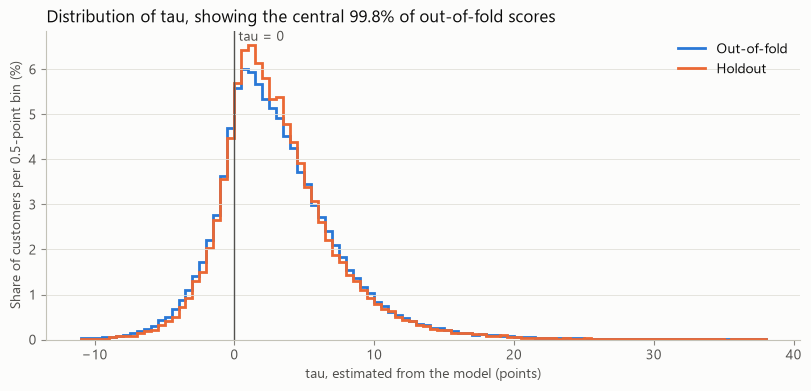

In [24]:
bin_width = 0.5
low, high = np.percentile(tau_oof * 100, [0.1, 99.9])
edges = np.arange(np.floor(low / bin_width) * bin_width, np.ceil(high / bin_width) * bin_width + bin_width, bin_width)
figure, axis = plt.subplots(figsize=(8, 3.8), layout="constrained")
for tau, label, color in ((tau_oof, "Out-of-fold", BLUE), (tau_holdout, "Holdout", ORANGE)):
    counts, _ = np.histogram(tau * 100, bins=edges)
    axis.stairs(counts / len(tau) * 100, edges, color=color, linewidth=2, label=label)
axis.axvline(0, color=INK_SECONDARY, linewidth=1)
axis.text(0, axis.get_ylim()[1], " tau = 0", color=INK_SECONDARY, va="top")
axis.set_xlabel("tau, estimated from the model (points)")
axis.set_ylabel(f"Share of customers per {bin_width}-point bin (%)")
axis.set_title("Distribution of tau, showing the central 99.8% of out-of-fold scores")
axis.legend(loc="upper right")
figure.savefig(FIGURES / "tau_distribution.png", dpi=160)
plt.show()

## 16. Applying the committed rules

Every table above is written first, so a stop still leaves its evidence on disk. Score files and models are not written until these rules and the quoted values below have passed. A calibration flag or a fold flag does not stop the notebook. A fold flag goes to the project owner before the evaluation phase.

In [25]:
m0_largest_gain = m0_importance.iloc[0]
m0_largest_single_auc = m0_importance.sort_values("single_feature_auc", ascending=False).iloc[0]
m0_largest_bin_gap = m0_calibration["gap_points"].abs().max()
interval_text = f"Outside {development_interval[0] * 100:+.4f} to {development_interval[1] * 100:+.4f} points"

phase4_rows = [
    ("m0 log-loss below baseline", f"{m0_log_loss:.5f} vs {m0_baseline_log_loss:.5f}", "Stop if not below", m0_log_loss >= m0_baseline_log_loss, "Stop"),
    (f"m0 largest gain share ({m0_largest_gain['feature']})", f"{m0_largest_gain['gain_share']:.4f}", f">= {GAIN_STOP}", m0_largest_gain["gain_share"] >= GAIN_STOP, "Stop"),
    (f"m0 largest single-feature AUC ({m0_largest_single_auc['feature']})", f"{m0_largest_single_auc['single_feature_auc']:.4f}", f">= {SINGLE_FEATURE_AUC_STOP}", m0_largest_single_auc["single_feature_auc"] >= SINGLE_FEATURE_AUC_STOP, "Stop"),
    ("m0 overall out-of-fold AUC", f"{m0_auc:.4f}", f">= {OVERALL_AUC_STOP}", m0_auc >= OVERALL_AUC_STOP, "Stop"),
    ("m0 calibration slope", f"{m0_calibration_slope:.4f}", f"Outside {SLOPE_RANGE[0]} to {SLOPE_RANGE[1]}", not SLOPE_RANGE[0] <= m0_calibration_slope <= SLOPE_RANGE[1], "Report and proceed"),
    ("m0 largest calibration bin gap (points)", f"{m0_largest_bin_gap:.2f}", f"> {BIN_GAP_FLAG_POINTS}", m0_largest_bin_gap > BIN_GAP_FLAG_POINTS, "Report and proceed"),
    ("Mean tau, out-of-fold (points)", f"{tau_oof.mean() * 100:+.4f}", interval_text, not development_interval[0] <= tau_oof.mean() <= development_interval[1], "Stop"),
    ("Mean tau, holdout (points)", f"{tau_holdout.mean() * 100:+.4f}", interval_text, not development_interval[0] <= tau_holdout.mean() <= development_interval[1], "Stop"),
]
for row in arm_balance_table.itertuples():
    phase4_rows.append((f"{row.score}: absolute SMD between arms", f"{abs(row.smd):.4f}", f">= {SMD_STOP}", abs(row.smd) >= SMD_STOP, "Stop"))
    phase4_rows.append((f"{row.score}: treated SD / control SD", f"{row.sd_ratio:.4f}", f"Outside {SD_RATIO_RANGE[0]} to {SD_RATIO_RANGE[1]}", not SD_RATIO_RANGE[0] <= row.sd_ratio <= SD_RATIO_RANGE[1], "Stop"))
    if row.score != "m0":
        phase4_rows.append((f"{row.score}: treated share of the top 20%", f"{row.treated_share_top_20:.4f}", f"Outside {TREATED_SHARE_RANGE[0]} to {TREATED_SHARE_RANGE[1]}", not TREATED_SHARE_RANGE[0] <= row.treated_share_top_20 <= TREATED_SHARE_RANGE[1], "Stop"))
for row in tau_by_fold.itertuples():
    phase4_rows.append((f"Fold {row.fold}: share of the pooled top 20%", f"{row.share_of_pooled_top_20:.4f}", f"Outside {FOLD_SHARE_FLAG_RANGE[0]} to {FOLD_SHARE_FLAG_RANGE[1]}", not FOLD_SHARE_FLAG_RANGE[0] <= row.share_of_pooled_top_20 <= FOLD_SHARE_FLAG_RANGE[1], "Bring to the project owner"))

phase4_decision = pd.DataFrame(phase4_rows, columns=["check", "measured", "threshold", "triggered", "action_if_triggered"])
phase4_decision.to_csv(TABLES / "uplift_decision.csv", index=False)
display(phase4_decision)

phase4_stops = phase4_decision[phase4_decision["triggered"] & (phase4_decision["action_if_triggered"] == "Stop")]
if len(phase4_stops):
    raise RuntimeError("Stop and investigate before the evaluation phase: " + "; ".join(phase4_stops["check"]))
print("No stop rule triggered.")

,check,measured,threshold,triggered,action_if_triggered
0,m0 log-loss below baseline,0.54519 vs 0.67166,Stop if not below,False,Stop
1,m0 largest gain share (txn_count_60d),0.2950,>= 0.5,False,Stop
2,m0 largest single-feature AUC (txn_count_60d),0.7621,>= 0.8,False,Stop
3,m0 overall out-of-fold AUC,0.7817,>= 0.9,False,Stop
4,m0 calibration slope,1.0007,Outside 0.9 to 1.1,False,Report and proceed
5,m0 largest calibration bin gap (points),0.45,> 2.0,False,Report and proceed
6,"Mean tau, out-of-fold (points)",+3.1902,Outside +2.8475 to +3.7982 points,False,Stop
7,"Mean tau, holdout (points)",+3.2366,Outside +2.8475 to +3.7982 points,False,Stop
8,m1: absolute SMD between arms,0.0061,>= 0.05,False,Stop
9,m1: treated SD / control SD,0.9995,Outside 0.9 to 1.1,False,Stop


No stop rule triggered.


### Measurements quoted in the documents

The conclusion below and `reports/decisions.md` quote these values, so a change must stop the run, before anything is written. A warned run skips them, because the freeze rule allows tiny differences that could change a rounded value.

In [26]:
if freeze_action == "warn":
    print("Warned run: quoted values not compared")
else:
    assert m1_match_gap == 0.0
    assert np.round(np.array(development_interval) * 100, 2).tolist() == [2.85, 3.8] and round(development_difference * 100, 2) == 3.32
    assert (round(y_dev[treated].mean() * 100, 2), round(y_dev[control].mean() * 100, 2)) == (63.65, 60.33)
    assert m0_metrics[["value", "ci_low", "ci_high"]].round(4).to_numpy().tolist() == [
        [0.7817, 0.7784, 0.7848],
        [0.5452, 0.5423, 0.5483],
        [0.6717, 0.6717, 0.6717],
        [-0.1265, -0.1294, -0.1234],
    ]
    assert (round(m0_fold_metrics["auc"].min(), 4), round(m0_fold_metrics["auc"].max(), 4)) == (0.7779, 0.7863)
    assert round(m0_calibration_slope, 4) == 1.0007 and round(m0_calibration_intercept, 4) == -0.0007
    assert round(m0_largest_bin_gap, 2) == 0.45 and m0_calibration.loc[m0_calibration["gap_points"].abs().idxmax(), "bin"] == 5
    assert (m0_largest_gain["feature"], round(m0_largest_gain["gain_share"], 4)) == ("txn_count_60d", 0.2950)
    assert (m0_largest_single_auc["feature"], round(m0_largest_single_auc["single_feature_auc"], 4)) == ("txn_count_60d", 0.7621)
    m0_express = m0_importance[m0_importance["feature"].str.startswith("express_")]
    assert (round(m0_express["gain_share"].max(), 4), round(m0_express["single_feature_auc"].max(), 4)) == (0.0012, 0.5057)
    assert arm_balance_table[["smd", "sd_ratio"]].round(4).to_numpy().tolist() == [[0.0061, 0.9995], [0.0063, 0.9990], [-0.0023, 0.9924]]
    assert arm_balance_table["treated_share_top_20"].dropna().round(4).tolist() == [0.5033, 0.4964]
    summary_points = tau_summary_table.set_index("rows").drop(columns="customers") * 100
    assert summary_points.round(2).to_numpy().tolist() == [
        [3.19, 4.79, 21.41, -25.47, -6.09, -2.99, -1.56, 0.33, 2.50, 5.36, 8.66, 11.23, 18.56, 60.00],
        [3.24, 4.71, 19.38, -20.38, -5.44, -2.55, -1.25, 0.50, 2.50, 5.17, 8.46, 11.06, 18.95, 58.34],
    ]
    assert (tau_by_fold["mean_tau"] * 100).round(2).tolist() == [3.22, 3.12, 3.14, 3.27, 3.20]
    assert (tau_by_fold["sd_tau"] * 100).round(2).tolist() == [4.80, 4.96, 4.64, 4.89, 4.66]
    assert (tau_by_fold["share_below_zero"] * 100).round(1).tolist() == [22.0, 22.6, 21.7, 20.7, 20.0]
    assert (tau_by_fold["share_of_pooled_top_20"] * 100).round(1).tolist() == [20.0, 20.3, 19.4, 20.8, 19.5]
    assert spearman["spearman_m1_tau"].round(3).tolist() == [-0.131, -0.143, -0.074, -0.185, -0.144, -0.113, -0.128]
    print("All quoted values match")

All quoted values match


## 17. Write to staging and check row alignment

Files go to a staging folder first. Each saved score file is reloaded and joined to the features by `client_id`, then rescored with both models, and must match exactly. Out-of-fold rows use this run's fold models, in both arms, before they are discarded. Holdout rows use the saved refit models. Neither mean `tau` nor arm balance can catch scores attached to the wrong customer.

In [27]:
shutil.rmtree(STAGING, ignore_errors=True)
STAGING.mkdir(parents=True)
staged_oof, staged_holdout = STAGING / SCORES_OOF_PATH.name, STAGING / SCORES_HOLDOUT_PATH.name
staged_m1, staged_m0 = STAGING / M1_MODEL_PATH.name, STAGING / M0_MODEL_PATH.name

pd.DataFrame({"client_id": client_ids_dev, "fold": fold_dev, "m1_score": m1_oof, "m0_score": m0_oof, "tau": tau_oof}).to_parquet(staged_oof, index=False)
pd.DataFrame({"client_id": client_ids_holdout, "m1_score": m1_holdout, "m0_score": m0_holdout, "tau": tau_holdout}).to_parquet(staged_holdout, index=False)
m1_refit.save_model(staged_m1)
m0_refit.save_model(staged_m0)


def scores_joined_to_features(path):
    connection = duckdb.connect()
    joined = connection.execute(
        f"""
        SELECT s.*, {', '.join(f'f.{name}' for name in FEATURE_NAMES)}
        FROM '{path}' AS s
        JOIN '{FEATURES_PATH}' AS f USING (client_id)
        ORDER BY s.client_id
        """
    ).fetchdf()
    connection.close()
    return joined


oof_rows = scores_joined_to_features(staged_oof)
assert len(oof_rows) == EXPECTED_DEVELOPMENT and {"treatment_flg", "target"}.isdisjoint(oof_rows.columns)
assert_exact_tau(oof_rows["m1_score"].to_numpy(), oof_rows["m0_score"].to_numpy(), oof_rows["tau"].to_numpy())
assert oof_rows["client_id"].tolist() == client_ids_dev and np.array_equal(oof_rows["fold"].to_numpy(dtype=int), fold_dev)
oof_features = oof_rows[FEATURE_NAMES].to_numpy(dtype=float, na_value=np.nan)
for fold in FOLDS:
    in_fold = oof_rows["fold"].to_numpy(dtype=int) == fold
    assert np.array_equal(m1_fold_models[fold].predict_proba(oof_features[in_fold])[:, 1], oof_rows.loc[in_fold, "m1_score"].to_numpy())
    assert np.array_equal(m0_fold_models[fold].predict_proba(oof_features[in_fold])[:, 1], oof_rows.loc[in_fold, "m0_score"].to_numpy())

holdout_rows = scores_joined_to_features(staged_holdout)
assert len(holdout_rows) == EXPECTED_HOLDOUT and {"treatment_flg", "target"}.isdisjoint(holdout_rows.columns)
assert_exact_tau(holdout_rows["m1_score"].to_numpy(), holdout_rows["m0_score"].to_numpy(), holdout_rows["tau"].to_numpy())
assert holdout_rows["client_id"].tolist() == expected_holdout_ids
holdout_features = holdout_rows[FEATURE_NAMES].to_numpy(dtype=float, na_value=np.nan)
reloaded_m1, reloaded_m0 = XGBClassifier(), XGBClassifier()
reloaded_m1.load_model(staged_m1)
reloaded_m0.load_model(staged_m0)
assert np.array_equal(reloaded_m1.predict_proba(holdout_features)[:, 1], holdout_rows["m1_score"].to_numpy())
assert np.array_equal(reloaded_m0.predict_proba(holdout_features)[:, 1], holdout_rows["m0_score"].to_numpy())

# Every labelled customer appears exactly once across the two files.
saved_ids = oof_rows["client_id"].tolist() + holdout_rows["client_id"].tolist()
assert len(saved_ids) == ALL_CUSTOMERS and set(saved_ids) == all_split_ids

del m1_fold_models, m0_fold_models, oof_rows, holdout_rows, oof_features, holdout_features
print("Row alignment and coverage checks passed")

Row alignment and coverage checks passed


In [28]:
MODELS.mkdir(exist_ok=True)
for staged, final in ((staged_oof, SCORES_OOF_PATH), (staged_holdout, SCORES_HOLDOUT_PATH), (staged_m1, M1_MODEL_PATH), (staged_m0, M0_MODEL_PATH)):
    os.replace(staged, final)
STAGING.rmdir()

if freeze_action == "first_run":
    pd.DataFrame({"m1_score": m1_holdout.astype(np.float64), "m0_score": m0_holdout.astype(np.float64)}).to_csv(
        REFERENCE_PATH, index=False, float_format="%.6f", lineterminator="\n"
    )
    written_reference = pd.read_csv(REFERENCE_PATH)
    assert max(
        np.abs(written_reference["m1_score"].to_numpy() - m1_holdout.astype(np.float64)).max(),
        np.abs(written_reference["m0_score"].to_numpy() - m0_holdout.astype(np.float64)).max(),
    ) <= 1e-6

final_holdout = pd.read_parquet(SCORES_HOLDOUT_PATH)
assert_exact_tau(final_holdout["m1_score"].to_numpy(), final_holdout["m0_score"].to_numpy(), final_holdout["tau"].to_numpy())
assert holdout_score_hash(final_holdout["client_id"].tolist(), final_holdout["m1_score"].to_numpy(), final_holdout["m0_score"].to_numpy()) == holdout_hash
print(f"Holdout scores SHA-256: {holdout_hash}")

Holdout scores SHA-256: b40d79c605f5447f7b0ba94eafbe0e30f1651aa0fcb266356a4f2b3fe33b6bc2


## Phase 4 conclusion

Values for `m0`, the development interval and arm balance are **Measured** on out-of-fold development rows. Values for `tau` are **Estimated from the model**.

- **Match with Phase 3:** `m1` out-of-fold scores on treated rows match Phase 3 exactly, with a largest difference of 0.0.
- **`m0`:** AUC 0.7817 (95% CI 0.7784 to 0.7848) and log-loss 0.5452 (0.5423 to 0.5483), against a baseline log-loss of 0.6717. Calibration slope 1.0007, largest bin gap 0.45 points. No stop rule or flag was triggered.
- **Mean `tau`:** +3.19 points out-of-fold and +3.24 points on the holdout, both inside the development interval of +2.85 to +3.80 points.
- **Arm balance:** the largest absolute SMD is 0.0063, every SD ratio is at least 0.9924, and the treated share of the top 20% is 50.33% for `m1` and 49.64% for `tau`.
- **Spread of `tau`:** SD 4.79 points out-of-fold and 4.71 on the holdout, with 21.41% and 19.38% of scores below zero.
- **Rank correlation of `m1` and `tau`:** -0.131 pooled out-of-fold and -0.128 on the holdout, ranging from -0.074 to -0.185 across folds.
- **Folds:** each fold holds 19.4% to 20.8% of the pooled top 20%, so no fold flag was raised.
- **Freeze:** the holdout scores match the recorded hash, and no holdout label was loaded in this phase.

**What this does not show:** whether ranking by `tau` finds more incremental purchasers than ranking by `m1`. Phase 4 never compares `tau` with `target`. The spread of `tau` also includes model noise, and nothing here shows how much of it reflects real differences between customers.